# Exploratory Data Analysis (EDA) and Principal Component Analysis (PCA)

**Learning goals:** inspect a real dataset, understand correlations, visualize PCA, quantify information loss, and evaluate a leakage-safe predictive pipeline.


## 1. Setup

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_iris, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. EDA: inspect the Iris dataset
We distinguish **predictor features** (measurements) from the **target label** (species).

In [24]:
iris = load_iris(as_frame=True)
features = list(iris.feature_names)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,dtype
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
species,str


### Data quality: missingness, duplicates, and summary statistics
Duplicates are *reported*, not automatically deleted: some identical measurements may be valid.

In [25]:
print("Missing values by column:")
display(df.isna().sum().to_frame("missing"))
print("Exact duplicate rows:", df.duplicated().sum())
display(df[features].describe().T)
display(df["species"].value_counts().to_frame("count"))

Missing values by column:


,missing
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


Exact duplicate rows: 1


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


,count
species,
setosa,50
versicolor,50
virginica,50


### Univariate distributions: histogram and boxplot
A histogram shows the shape of the distribution; a boxplot emphasizes quartiles and possible outliers.

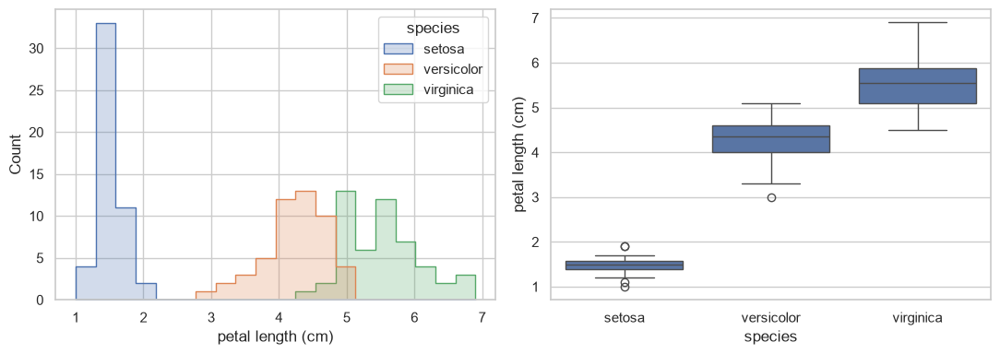

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="petal length (cm)", hue="species", bins=20, element="step", ax=axes[0])
sns.boxplot(data=df, x="species", y="petal length (cm)", ax=axes[1])
fig.tight_layout()
plt.show()

### Relationships between numerical features
Pairplots reveal dependencies and class patterns. Correlation quantifies **linear association**, not causation or independence.

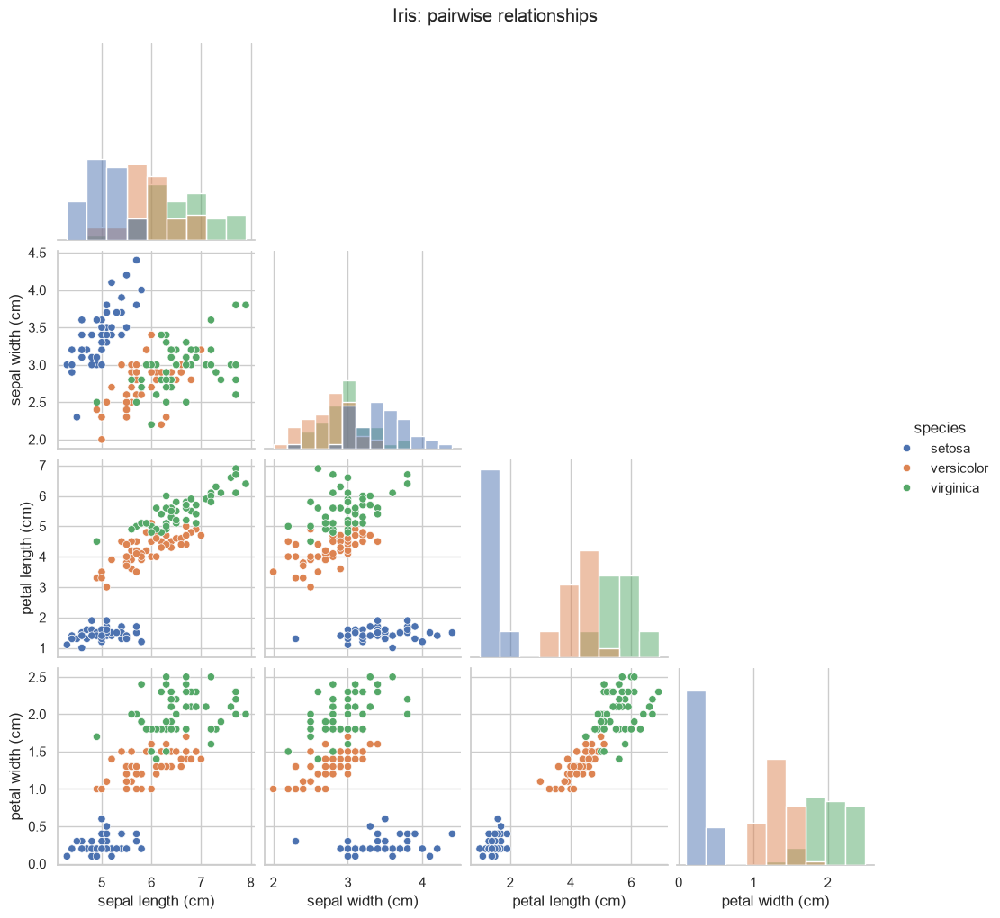

In [44]:
g = sns.pairplot(df, vars=features, hue="species", diag_kind="hist", corner=True)
g.figure.suptitle("Iris: pairwise relationships", y=1.02)
plt.show()

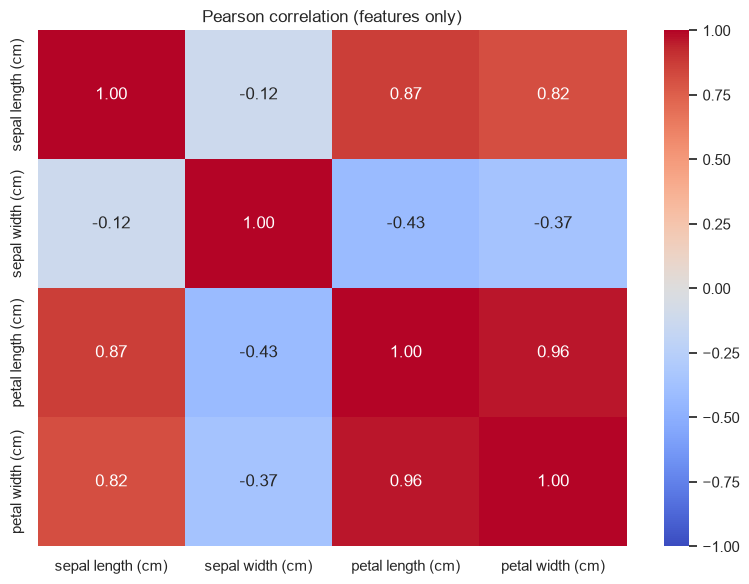

In [28]:
corr = df[features].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson correlation (features only)")
plt.tight_layout()
plt.show()

**Question:** Which two measurements are most strongly correlated? Do you expect PCA to compress this dataset effectively?

## 3. PCA geometry on synthetic data
PC1 follows the greatest spread of centered observations; PC2 is orthogonal to PC1.

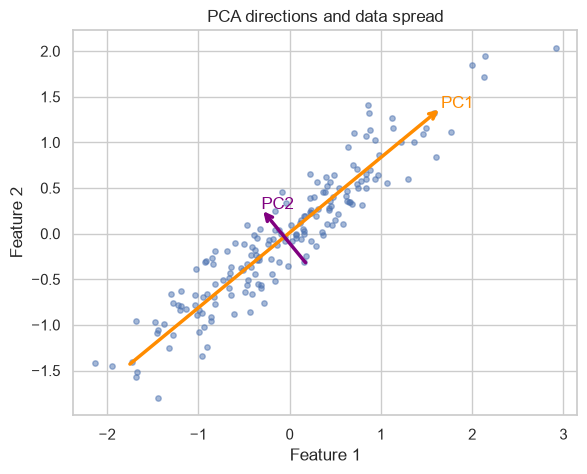

In [29]:
rng = np.random.default_rng(RANDOM_STATE)
x = rng.normal(size=180)
y = 0.8*x + rng.normal(scale=0.25, size=len(x))
cloud = np.column_stack([x, y])

geo_pca = PCA(n_components=2).fit(cloud)

center = cloud.mean(axis=0)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(*cloud.T, s=15, alpha=0.5)
for j, color in enumerate(["darkorange", "purple"]):
    direction = geo_pca.components_[j] * 2 * np.sqrt(geo_pca.explained_variance_[j])
    ax.annotate("", xy=center+direction, xytext=center-direction,
                arrowprops=dict(arrowstyle="->", lw=2.5, color=color))
    ax.text(*(center+direction), f"PC{j+1}", color=color)
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="PCA directions and data spread")
ax.set_aspect("equal", adjustable="datalim")
plt.show()

## 4. PCA on Iris: standardize, fit, and visualize
Scaling is important when variables are expressed in different units or have very different numerical ranges.

In [30]:
X = df[features]
y = iris.target.to_numpy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca_full = PCA().fit(X_scaled)
Z = pca_full.transform(X_scaled)
print("Explained variance ratio:", np.round(pca_full.explained_variance_ratio_, 3))
print("Cumulative variance:", np.round(np.cumsum(pca_full.explained_variance_ratio_), 3))
components = pd.DataFrame(pca_full.components_.T, index=features, columns=[f"PC{i+1}" for i in range(4)])
display(components)

Explained variance ratio: [0.73  0.229 0.037 0.005]
Cumulative variance: [0.73  0.958 0.995 1.   ]


,PC1,PC2,PC3,PC4
sepal length (cm),0.521066,0.377418,0.719566,-0.261286
sepal width (cm),-0.269347,0.923296,-0.244382,0.123510
petal length (cm),0.580413,0.024492,-0.142126,0.801449
petal width (cm),0.564857,0.066942,-0.634273,-0.523597


Large absolute values indicate strong contributions.

For example, if petal length and petal width both have large loadings on PC1, PC1 may represent a general **petal-size direction**.

The sign should not be over-interpreted: multiplying an entire principal component by `-1` describes the same PCA solution.

<Figure size 700x500 with 0 Axes>

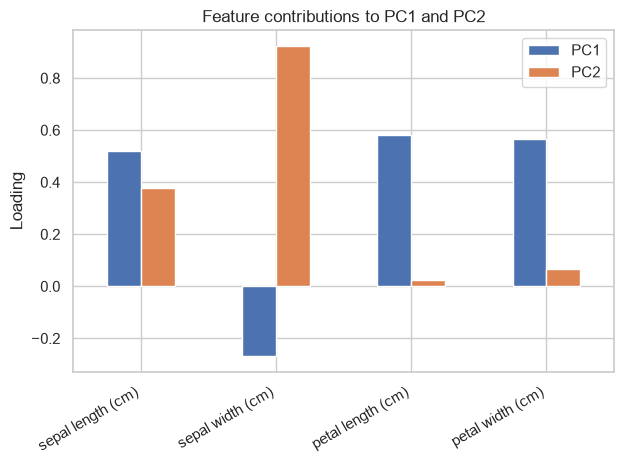

In [31]:
plt.figure(figsize=(7, 5))

components[["PC1", "PC2"]].plot(
    kind="bar"
)

plt.ylabel("Loading")
plt.title("Feature contributions to PC1 and PC2")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

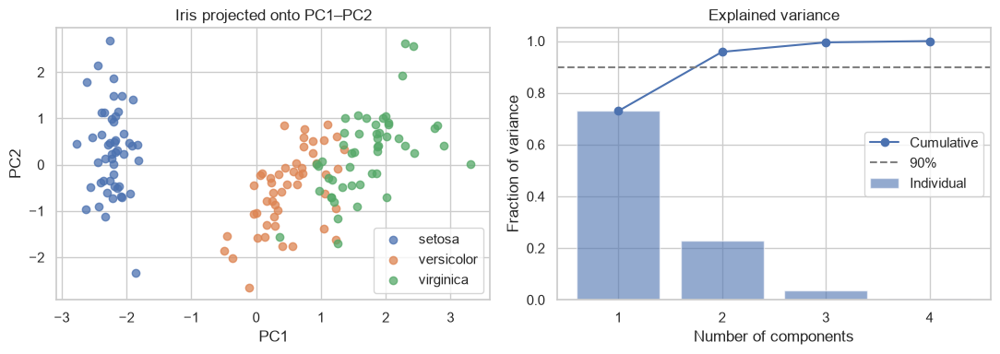

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for target, name in enumerate(iris.target_names):
    mask = y == target
    axes[0].scatter(Z[mask, 0], Z[mask, 1], label=name, alpha=0.75)
axes[0].set(xlabel="PC1", ylabel="PC2", title="Iris projected onto PC1–PC2")
axes[0].legend()
ratio = pca_full.explained_variance_ratio_
axes[1].bar(np.arange(1, len(ratio)+1), ratio, alpha=0.6, label="Individual")
axes[1].plot(np.arange(1, len(ratio)+1), np.cumsum(ratio), marker="o", label="Cumulative")
axes[1].axhline(0.90, ls="--", color="gray", label="90%")
axes[1].set(xlabel="Number of components", ylabel="Fraction of variance", xticks=range(1,5), title="Explained variance")
axes[1].legend()
fig.tight_layout()
plt.show()

### Approximate reconstruction
We use 1, 2, 3, or 4 components and reconstruct in **standardized** feature space. The reconstruction error should decrease as components are retained.

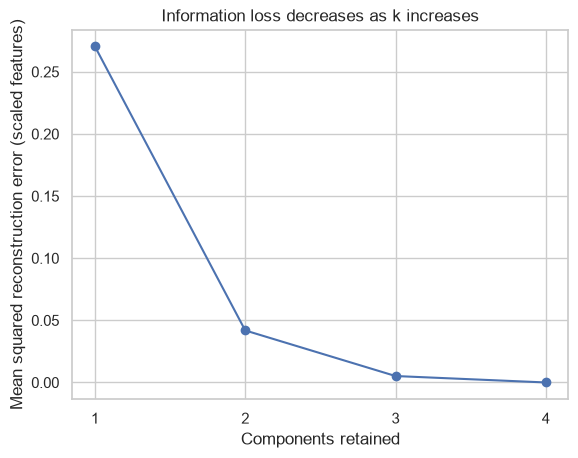

   k  reconstruction_MSE
0  1        2.703755e-01
1  2        4.186793e-02
2  3        5.178709e-03
3  4        3.457121e-31


In [33]:
errors = []
for k in range(1, 5):
    reduced = PCA(n_components=k).fit(X_scaled)
    reconstructed = reduced.inverse_transform(reduced.transform(X_scaled))
    errors.append(np.mean((X_scaled - reconstructed)**2))
plt.plot(range(1,5), errors, marker="o")
plt.xlabel("Components retained")
plt.ylabel("Mean squared reconstruction error (scaled features)")
plt.title("Information loss decreases as k increases")
plt.xticks(range(1,5))
plt.show()
print(pd.DataFrame({"k": range(1,5), "reconstruction_MSE": errors}))

### Why PCA minimizes squared reconstruction error (geometric animation)

Suppose we want to represent **2D centered observations with a single number**. We choose a unit vector $w=(\cos\theta,\sin\theta)$ defining a line through the origin. For each point $x_i$:

1. **Project onto the line:** $z_i=x_i^\top w$ (one scalar score).
2. **Reconstruct in 2D:** $\hat x_i=z_iw=ww^\top x_i$.
3. **Measure the loss:** $\|x_i-\hat x_i\|_2^2$. The dashed segment in the animation joins the original point to its projection.

The total **squared reconstruction loss** is

$$E(w)=\sum_{i=1}^n\|x_i-\hat x_i\|_2^2.$$

Since the projection is **orthogonal**, the Pythagorean theorem gives

$$\underbrace{\sum_i\|x_i\|_2^2}_{\text{total centered variation}}
=\underbrace{\sum_i\|\hat x_i\|_2^2}_{\text{retained variation}}
+\underbrace{\sum_i\|x_i-\hat x_i\|_2^2}_{\text{reconstruction loss}}.$$

The left-hand side is fixed. Therefore **maximizing retained variance is equivalent to minimizing squared reconstruction loss**. For an orthonormal basis $W_k$ of a $k$-dimensional subspace, $Z=X_cW_k$ and $\hat X_c=ZW_k^\top$; PCA chooses $W_k$ that minimizes $\|X_c-\hat X_c\|_F^2$. More precisely, sample retained variance equals $\|Z\|_F^2/(n-1)$.

**Watch:** As the projection line rotates, the dashed residuals and the squared error change. The **PCA direction** (shown dashed in green) is the line with the smallest loss. Its opposite direction represents the *same* 1D subspace.

Maximizing the spread *along* the projection line the same as minimizing distances *perpendicular* to it?


In [34]:
# Rotating a 1D subspace: retained variance versus reconstruction loss
# Requires numpy, matplotlib and IPython (no external dataset or ipywidgets needed).
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(11)
t = rng.normal(size=22)
X_demo = np.column_stack((1.6*t + rng.normal(scale=0.24, size=len(t)),
                          0.85*t + rng.normal(scale=0.24, size=len(t))))
X_demo -= X_demo.mean(axis=0)  # center so the optimal affine line passes through 0

# SVD gives the best 1D PCA axis, without using sklearn.
_, _, Vt = np.linalg.svd(X_demo, full_matrices=False)
w_pca = Vt[0]
pca_angle = np.arctan2(w_pca[1], w_pca[0]) % np.pi  # axes w and -w are identical
angles = np.linspace(0, np.pi, 75, endpoint=False)

# The same squared norm is split between projection and perpendicular residual.
total_sq = np.sum(X_demo**2)
def project_and_score(theta):
    w = np.array([np.cos(theta), np.sin(theta)])
    scores = X_demo @ w
    reconstructed = np.outer(scores, w)
    squared_error = np.sum((X_demo - reconstructed)**2)
    retained = np.sum(reconstructed**2)
    return reconstructed, squared_error, retained

loss_curve = np.array([project_and_score(a)[1] for a in angles])
fig, (ax, axloss) = plt.subplots(1, 2, figsize=(11, 4.6))
ax.scatter(X_demo[:, 0], X_demo[:, 1], color='tab:blue', s=22, label='Original points', zorder=3)
lim = max(3.2, np.max(np.abs(X_demo))*1.15)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel='$x_1$', ylabel='$x_2$',
       title='Projection onto a rotating line')
ax.set_aspect('equal', adjustable='box')

# The reference PCA line is fixed.
a = np.array([np.cos(pca_angle), np.sin(pca_angle)])
ax.plot([-lim*a[0], lim*a[0]], [-lim*a[1], lim*a[1]],
        color='tab:green', ls='--', lw=1.8, label='Optimal PCA axis')
rotating_line, = ax.plot([], [], color='tab:orange', lw=2, label='Current axis')
projected_points = ax.scatter([], [], color='tab:red', s=20, zorder=4, label='Projections')
residual_lines, = ax.plot([], [], color='0.55', lw=0.9, alpha=0.8)
ax.legend(loc='upper left', fontsize=8)

axloss.plot(np.degrees(angles), loss_curve, color='0.35', lw=2)
axloss.axvline(np.degrees(pca_angle), color='tab:green', ls='--', label='PCA optimum')
marker, = axloss.plot([], [], 'o', color='tab:orange', ms=8)
axloss.set(xlim=(0, 180), ylim=(0, max(loss_curve)*1.12),
           xlabel='Axis angle (degrees)', ylabel='Total squared reconstruction error',
           title='Reconstruction loss versus angle')
axloss.legend(fontsize=8)
status = axloss.text(0.03, 0.96, '', transform=axloss.transAxes, va='top', fontsize=9)

# Include the optimum angle explicitly, even if the animation grid skips over it.
frame_angles = np.r_[angles, pca_angle]
def update(frame):
    theta = frame_angles[frame]
    w = np.array([np.cos(theta), np.sin(theta)])
    P, error, retained = project_and_score(theta)
    rotating_line.set_data([-lim*w[0], lim*w[0]], [-lim*w[1], lim*w[1]])
    projected_points.set_offsets(P)
    # Plot separate dashed segments using NaN separators.
    segments = np.stack([X_demo, P, np.full_like(P, np.nan)], axis=1).reshape(-1, 2)
    residual_lines.set_data(segments[:, 0], segments[:, 1])
    marker.set_data([np.degrees(theta)], [error])
    status.set_text(f'Error = {error:.2f}\nRetained = {100*retained/total_sq:.1f}%')
    return rotating_line, projected_points, residual_lines, marker, status

anim = FuncAnimation(fig, update, frames=len(frame_angles), interval=120, blit=False, repeat=True)
plt.close(fig)  # avoid a duplicate static plot in Jupyter
# Embedded HTML animation: works in Jupyter Notebook and Colab without an external video encoder.
display(HTML(anim.to_jshtml(default_mode='loop')))

# Numerical check of Pythagoras and optimality.
P_best, E_best, kept_best = project_and_score(pca_angle)
assert np.isclose(E_best + kept_best, total_sq)
assert E_best <= loss_curve.min() + 1e-8
print(f'PCA angle (modulo 180°): {np.degrees(pca_angle):.1f}°')
print(f'PCA minimum squared error: {E_best:.4f}')

PCA angle (modulo 180°): 28.7°
PCA minimum squared error: 0.8528


## 5. Does maximum variance imply maximum predictive usefulness?
No. PCA is unsupervised and does not optimize accuracy. We evaluate with a held-out test set, fitting every transformation **inside** a pipeline.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
models = {
    "Scaled logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "PCA(2) + logistic regression": make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=1000)),
    "PCA(3) + logistic regression": make_pipeline(StandardScaler(), PCA(n_components=3), LogisticRegression(max_iter=1000)),
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append((name, accuracy_score(y_test, model.predict(X_test))))
display(pd.DataFrame(results, columns=["Model", "Held-out accuracy"]))

,Model,Held-out accuracy
0,Scaled logistic regression,0.911111
1,PCA(2) + logistic regression,0.888889
2,PCA(3) + logistic regression,0.911111


## 6. Guided exercise: Wine dataset
Wine contains 13 numerical measurements and three classes. Investigate the following: missingness, correlations, scaling, variance explained, and classification performance.

In [36]:
wine = load_wine(as_frame=True)
X_wine = wine.data.copy()
y_wine = wine.target
print("Wine shape:", X_wine.shape)
display(X_wine.describe().T)
print("Missing entries:", int(X_wine.isna().sum().sum()))

Wine shape: (178, 13)


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Missing entries: 0


## Compare PCA on raw and standardized values
Do different units make one feature dominate? Compare explained variance and the PC1–PC2 projections.

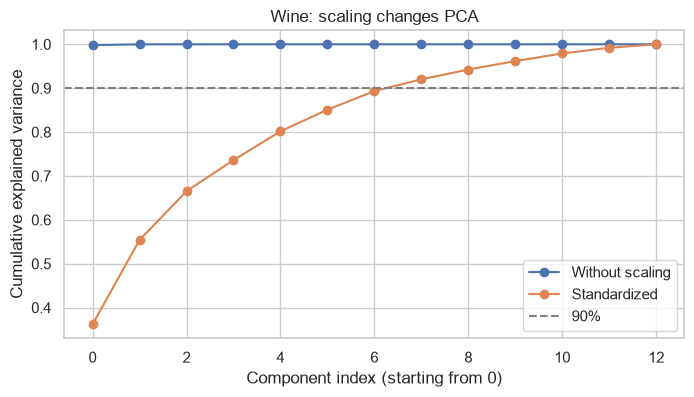

For 90% explained variance, standardized Wine needs 8 components.
For 95% explained variance, standardized Wine needs 10 components.


In [37]:
pca_raw = PCA().fit(X_wine)
wine_scaled = StandardScaler().fit_transform(X_wine)
pca_scaled = PCA().fit(wine_scaled)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(np.cumsum(pca_raw.explained_variance_ratio_), marker="o", label="Without scaling")
ax.plot(np.cumsum(pca_scaled.explained_variance_ratio_), marker="o", label="Standardized")
ax.axhline(0.90, color="gray", ls="--", label="90%")
ax.set(xlabel="Component index (starting from 0)", ylabel="Cumulative explained variance", title="Wine: scaling changes PCA")
ax.legend()
plt.show()
for threshold in (0.90, 0.95):
    needed = np.searchsorted(np.cumsum(pca_scaled.explained_variance_ratio_), threshold) + 1
    print(f"For {threshold:.0%} explained variance, standardized Wine needs {needed} components.")

### Wine case study: why scaling changes the meaning of explained variance

The Wine dataset has **13 chemical measurements** with very different numerical scales. For example, *proline* has much larger numerical variance than variables such as *hue* or *nonflavanoid_phenols*.

**Two distinct PCA objectives:**

- **Center only (covariance PCA):** $S=\frac{1}{n-1}X_c^\top X_c$. PC1 maximizes variance in the **original units**. A variable such as *proline* may dominate because of its magnitude.
- **Standardize first (correlation PCA):** $Z_{ij}=(X_{ij}-\bar X_j)/s_j$, then run PCA on $Z$. Each feature starts with unit variance (up to the standard-deviation convention), so PCA now summarizes **relative standardized variation**.

The explained variance ratio is $r_j=\lambda_j/\sum_\ell\lambda_\ell$ **within each feature space**. Therefore, 99% explained variance for raw PCA and 40% for standardized PCA are **not comparable measures of representation quality**: their denominators represent different total variances.

**What to look for in the plots below:**
1. The raw PCA scree plot is dominated by PC1, whereas standardized PCA spreads variance across multiple PCs.
2. The cumulative-variance curves reach 90% after different numbers of components; this is not automatically evidence in favor of raw PCA.
3. Compare the **PC1 coefficients**: which features define the direction? The score plots show how the three wine classes appear in the two representations, but do **not** establish predictive performance.

**Discussion:** Which choice is appropriate if the scientific goal is to describe different chemical characteristics fairly? Could retaining the original units be defensible in another application? To choose preprocessing for classification, evaluate complete pipelines on held-out data or through cross-validation.

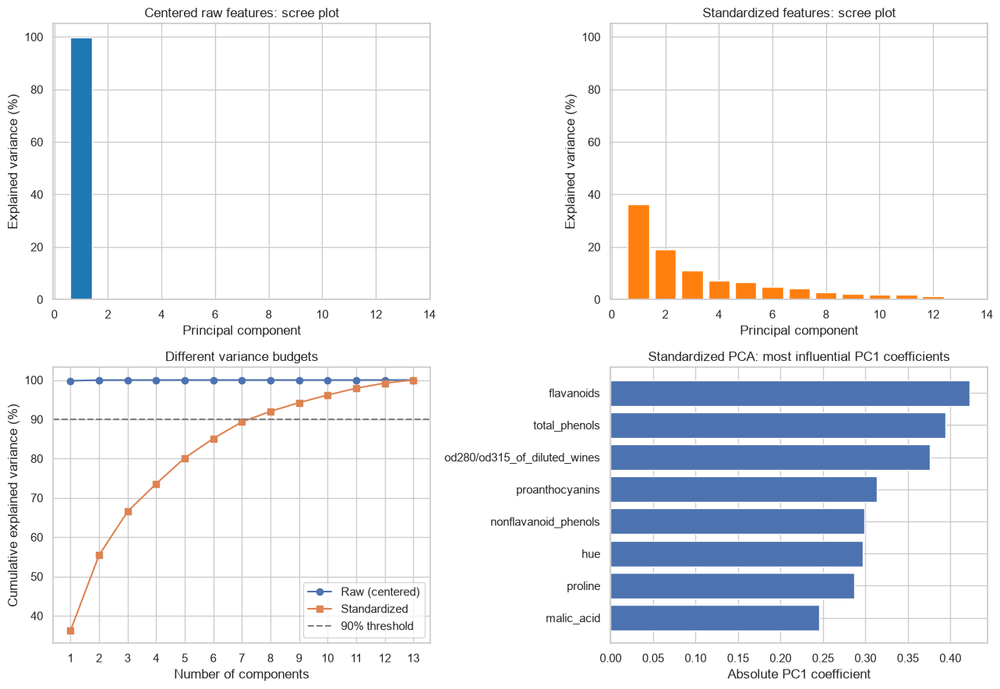

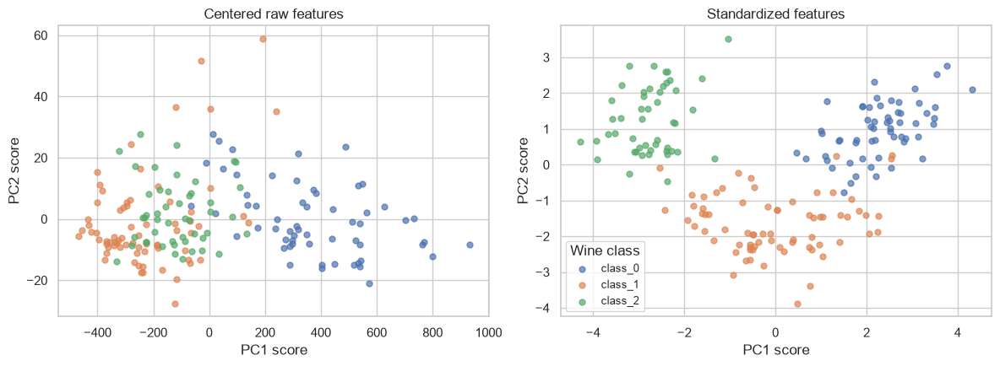

Raw          PC1=99.81%, PC1+PC2=99.98%, k90=1, k95=1
Standardized PC1=36.20%, PC1+PC2=55.41%, k90=8, k95=10
Raw PCA dominant PC1 feature: proline
Remember: more explained variance does not imply better classification.


In [38]:
# Wine: covariance PCA versus correlation PCA (run after the Wine dataset cells)
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

wine = load_wine(as_frame=True)
X_wine = wine.data
labels = wine.target.to_numpy()

raw_pca = PCA().fit(X_wine)  # PCA centers internally; it does NOT standardize
Xs = StandardScaler().fit_transform(X_wine)
std_pca = PCA().fit(Xs)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for model, name, color in [(raw_pca, 'Centered raw features', 'tab:blue'),
                           (std_pca, 'Standardized features', 'tab:orange')]:
    ev = model.explained_variance_ratio_
    a = ax[0, 0] if name.startswith('Centered') else ax[0, 1]
    a.bar(np.arange(1, len(ev)+1), ev*100, color=color)
    a.set_title(name + ': scree plot')
    a.set_xlabel('Principal component')
    a.set_ylabel('Explained variance (%)')
    a.set_ylim(0, 105)

ax[1, 0].plot(np.arange(1, 14), np.cumsum(raw_pca.explained_variance_ratio_)*100,
              'o-', label='Raw (centered)')
ax[1, 0].plot(np.arange(1, 14), np.cumsum(std_pca.explained_variance_ratio_)*100,
              's-', label='Standardized')
ax[1, 0].axhline(90, ls='--', color='gray', label='90% threshold')
ax[1, 0].set(xlabel='Number of components', ylabel='Cumulative explained variance (%)',
             title='Different variance budgets')
ax[1, 0].set_xticks(range(1,14))
ax[1, 0].legend()

# PC1 unit-vector coefficients; each panel uses its own feature coordinate system.
# Values are not directly comparable across the raw and standardized spaces.
order = np.argsort(np.abs(std_pca.components_[0]))[-8:]
ax[1, 1].barh(np.arange(len(order)), np.abs(std_pca.components_[0, order]))
ax[1, 1].set_yticks(np.arange(len(order)), X_wine.columns[order])
ax[1, 1].set(xlabel='Absolute PC1 coefficient',
             title='Standardized PCA: most influential PC1 coefficients')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for a, pca, data, name in [(axes[0], raw_pca, X_wine, 'Centered raw features'),
                            (axes[1], std_pca, Xs, 'Standardized features')]:
    scores = pca.transform(data)
    for category in np.unique(labels):
        sel = labels == category
        a.scatter(scores[sel, 0], scores[sel, 1], alpha=.7, s=25,
                  label=wine.target_names[category])
    a.set(xlabel='PC1 score', ylabel='PC2 score', title=name)
axes[1].legend(title='Wine class', fontsize=9)
plt.tight_layout()
plt.show()

for name, model in [('Raw', raw_pca), ('Standardized', std_pca)]:
    ratios = model.explained_variance_ratio_
    print(f'{name:12} PC1={ratios[0]:.2%}, PC1+PC2={sum(ratios[:2]):.2%}, '
          f'k90={np.searchsorted(np.cumsum(ratios), .90)+1}, '
          f'k95={np.searchsorted(np.cumsum(ratios), .95)+1}')

print('Raw PCA dominant PC1 feature:', X_wine.columns[np.argmax(np.abs(raw_pca.components_[0]))])
print('Remember: more explained variance does not imply better classification.')

## PCA scatter and interpretation
Can you distinguish the wine categories? What do PC1 and PC2 summarize?

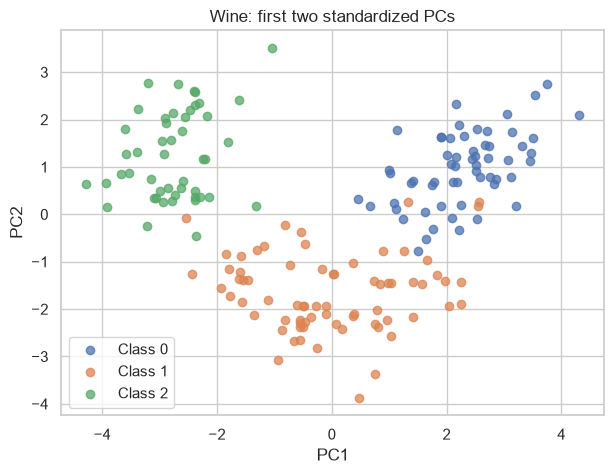

,PC1,PC2
flavanoids,0.422934,-0.003360
total_phenols,0.394661,0.065040
od280/od315_of_diluted_wines,0.376167,-0.164496
proanthocyanins,0.313429,0.039302
nonflavanoid_phenols,-0.298533,0.028779
hue,0.296715,-0.279235
proline,0.286752,0.364903


In [39]:
wine_scores = pca_scaled.transform(wine_scaled)
fig, ax = plt.subplots(figsize=(7, 5))
for label in sorted(y_wine.unique()):
    mask = y_wine.to_numpy() == label
    ax.scatter(wine_scores[mask, 0], wine_scores[mask, 1], alpha=0.75, label=f"Class {label}")
ax.set(xlabel="PC1", ylabel="PC2", title="Wine: first two standardized PCs")
ax.legend()
plt.show()
loading_wine = pd.DataFrame(pca_scaled.components_[:2].T, index=X_wine.columns, columns=["PC1", "PC2"])
display(loading_wine.sort_values("PC1", key=lambda s: s.abs(), ascending=False).head(7))

### Exercise C: a leak-free model comparison
Use stratified cross-validation; the pipeline refits scaler and PCA within each training fold.

In [40]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "No PCA": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "PCA(2)": make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=2000)),
    "PCA(95% variance)": make_pipeline(StandardScaler(), PCA(n_components=0.95), LogisticRegression(max_iter=2000)),
}
for name, pipeline in candidates.items():
    scores = cross_val_score(pipeline, X_wine, y_wine, cv=cv, scoring="accuracy")
    print(f"{name:20s}: {scores.mean():.3f} ± {scores.std():.3f}")

No PCA              : 0.983 ± 0.014
PCA(2)              : 0.955 ± 0.022
PCA(95% variance)   : 0.983 ± 0.014


## Example — Why PCA must center the features

**Question:** What happens if we search for the principal direction without subtracting feature means?

A standard PCA finds a *line through the mean of the observations*. This line minimizes the sum of squared **orthogonal reconstruction errors**. Centering is therefore important: PCA should describe how the data **vary around their mean**, not where the cloud happens to be located relative to the origin.

We will compare two rank-one approximations of a 2D dataset with a large vertical offset:

- **Correct PCA (centered):** $X_c=X-\mu$, $w_c$ is the leading eigenvector of $\frac{1}{n-1}X_c^\top X_c$; reconstruction $\widehat X_c=(X-\mu)w_cw_c^\top+\mu$.
- **Uncentered SVD (not standard PCA):** $w_0$ is the leading eigenvector of $\frac{1}{n}X^\top X$; reconstruction $\widehat X_0=Xw_0w_0^\top$. The fitted line is *forced through the origin*, so the mean offset influences its direction.

For a chosen direction $w$ with $\|w\|=1$, the squared reconstruction loss is

$$\mathrm{SSE}=\sum_{i=1}^n \|x_i-\hat x_i\|_2^2.$$

**Prediction:** the uncentered method will point toward the *location* of the cloud, while standard PCA will follow its *elongation*. Move the cloud without changing its shape: proper PCA directions should remain unchanged, while uncentered ones can change.

> **Technical distinction:** `sklearn.decomposition.PCA` **always centers** features internally, even without `StandardScaler`. The uncentered method below uses an SVD directly on $X$; it is not what `PCA().fit(X)` computes. Centering and scaling are separate choices.


Dataset mean: [-0.36  7.79]
Centered PCA SSE:   6.37
Uncentered SVD SSE: 510.11
Loss ratio (uncentered / centered): 80.1x


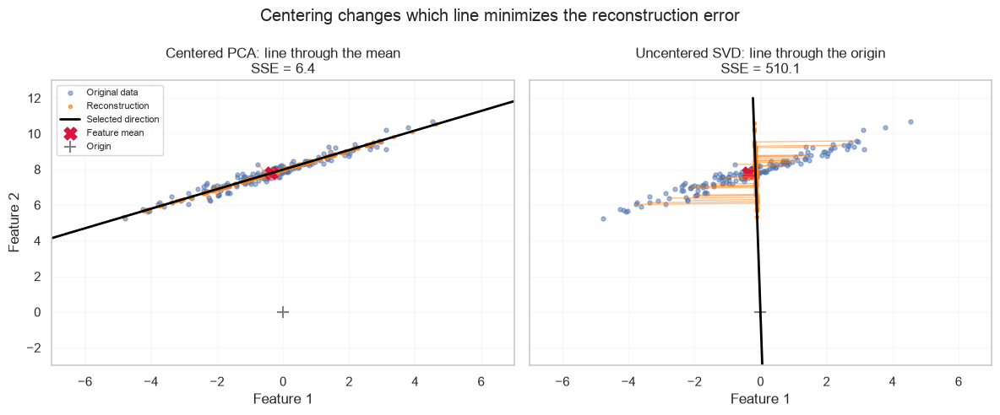

Absolute cosine between centered PCA directions before/after translation: 1.0


In [41]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

rng = np.random.default_rng(7)
n = 160
t = rng.normal(size=n) * 2.0
# Elongated cloud whose CENTER is far from the origin.
X = np.column_stack([t + rng.normal(scale=0.22, size=n),
                     0.55*t + rng.normal(scale=0.22, size=n) + 8.0])
mu = X.mean(axis=0)

# 1) Correct centered PCA (scikit-learn centers internally)
pca = PCA(n_components=1)
Z = pca.fit_transform(X)
X_rec_centered = pca.inverse_transform(Z)
w_centered = pca.components_[0]

# 2) Uncentered rank-1 approximation: SVD of raw X
_, _, Vt = np.linalg.svd(X, full_matrices=False)
w_uncentered = Vt[0]
X_rec_uncentered = (X @ w_uncentered[:, None]) @ w_uncentered[None, :]

sse_centered = np.sum((X - X_rec_centered)**2)
sse_uncentered = np.sum((X - X_rec_uncentered)**2)
print(f"Dataset mean: {mu.round(2)}")
print(f"Centered PCA SSE:   {sse_centered:.2f}")
print(f"Uncentered SVD SSE: {sse_uncentered:.2f}")
print(f"Loss ratio (uncentered / centered): {sse_uncentered/sse_centered:.1f}x")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, w, rec, title, sse, anchor in [
    (axes[0], w_centered, X_rec_centered, 'Centered PCA: line through the mean', sse_centered, mu),
    (axes[1], w_uncentered, X_rec_uncentered, 'Uncentered SVD: line through the origin', sse_uncentered, np.zeros(2)),
]:
    for original, projected in zip(X[::5], rec[::5]):
        ax.plot([original[0], projected[0]], [original[1], projected[1]],
                color='tab:orange', alpha=.5, lw=1)
    ax.scatter(X[:, 0], X[:, 1], s=13, alpha=.5, label='Original data')
    ax.scatter(rec[:, 0], rec[:, 1], s=9, alpha=.65, color='tab:orange', label='Reconstruction')
    q = np.linspace(-12, 12, 2)
    line = anchor[None, :] + q[:, None] * w[None, :]
    ax.plot(line[:, 0], line[:, 1], color='black', lw=2, label='Selected direction')
    ax.scatter(*mu, marker='X', s=115, color='crimson', label='Feature mean')
    ax.scatter(0, 0, marker='+', s=110, color='gray', label='Origin')
    ax.set_title(f'{title}\nSSE = {sse:.1f}')
    ax.set_xlabel('Feature 1')
    ax.grid(alpha=.15)
axes[0].set_ylabel('Feature 2')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].set_xlim(-7, 7)
axes[0].set_ylim(-3, 13)
fig.suptitle('Centering changes which line minimizes the reconstruction error')
plt.tight_layout()
plt.show()

# Additional check: translating the whole cloud does not change centered PCA's direction.
X_shifted = X + np.array([5.0, -3.0])
pca_shifted = PCA(n_components=1).fit(X_shifted)
print('Absolute cosine between centered PCA directions before/after translation:',
      round(abs(np.dot(w_centered, pca_shifted.components_[0])), 8))


## When linear PCA misses nonlinear structure: PCA vs Kernel PCA

**Question.** Can a one-dimensional representation distinguish observations belonging to two concentric circles?

Ordinary PCA searches for a **linear** direction $w$ and computes the score $z=x^\top w$ (after centering). It retains variance along a straight axis. For two concentric circles, observations from both classes overlap along *every* line through the center: their distinguishing information is primarily **radial**, rather than linear. A large explained-variance ratio does not ensure class separation.

**Kernel PCA** first represents observations implicitly in a nonlinear feature space $\phi(x)$, then performs PCA there. With the radial basis function (RBF) kernel,

$$k(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|_2^2),$$

we can compute nonlinear component scores without explicitly constructing $\phi(x)$. The first nonlinear component can separate the circles in this example.

**What to inspect:** (1) original data, (2) the 1D scores from linear PCA vs Kernel PCA, and (3) test accuracy of a *linear* classifier trained on those scores. The example deliberately chooses $\gamma=3$; Kernel PCA is sensitive to this hyperparameter. **Kernel PCA does not guarantee better results on every dataset**, and the retained variance of linear PCA is not directly comparable to a variance ratio in a different kernel feature space.


Linear PCA: test accuracy with 1D scores = 48.7%
RBF Kernel PCA: test accuracy with 1D scores = 100.0%


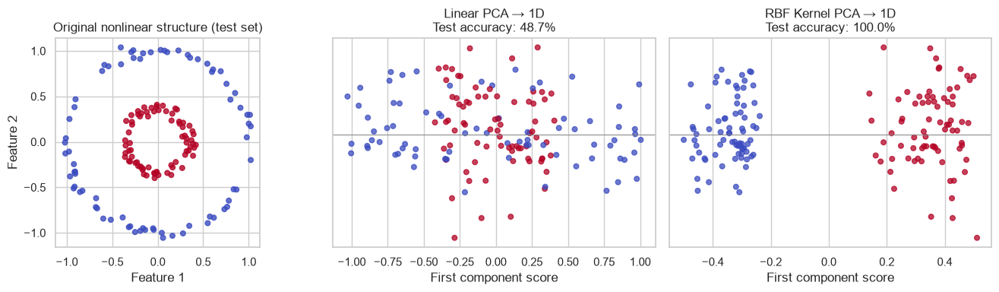

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.decomposition import PCA, KernelPCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Two classes arranged on concentric circles.
X, y = make_circles(n_samples=500, factor=0.35, noise=0.04, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

# Both transforms are fitted ONLY on training observations.
methods = {
    "Linear PCA": PCA(n_components=1),
    "RBF Kernel PCA": KernelPCA(n_components=1, kernel="rbf", gamma=3),
}
results = {}
for name, reducer in methods.items():
    z_train = reducer.fit_transform(X_train)
    z_test = reducer.transform(X_test)
    classifier = LogisticRegression(max_iter=1000).fit(z_train, y_train)
    accuracy = classifier.score(z_test, y_test)
    results[name] = (z_test[:, 0], accuracy)
    print(f"{name}: test accuracy with 1D scores = {accuracy:.1%}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=23, alpha=0.8)
axes[0].set_title("Original nonlinear structure (test set)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].set_aspect("equal")

rng = np.random.default_rng(123)
jitter = rng.normal(0, 0.025, size=len(y_test))  # purely for visualization
for ax, (name, (scores, accuracy)) in zip(axes[1:], results.items()):
    ax.scatter(scores, jitter, c=y_test, cmap="coolwarm", s=23, alpha=0.75)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set_title(f"{name} → 1D\nTest accuracy: {accuracy:.1%}")
    ax.set_xlabel("First component score")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# Interpretation: linear PCA can preserve large geometric spread but still mix
# the classes; RBF Kernel PCA captures a nonlinear radial distinction here.
